<a href="https://colab.research.google.com/github/AriyaAzamatova/Kazakh_Latin_Signs_Almaty_2026/blob/main/%D0%A0%D0%B8%D1%81%D1%83%D0%BD%D0%BE%D0%BA_2_(%D1%80%D0%B0%D0%B7%D0%B4%D0%B5%D0%BB_5_2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

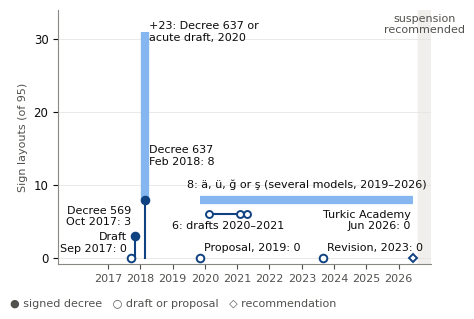

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# Рисунок 2 (раздел 5.2): макеты со знаками документов казахской латиницы, 2017–2026 гг.
# Версия 15.11.2026 (2): 95 макетов; правки оформления: шрифты TrueType в PDF (fonttype 42),
# подписи Draft и Decree 569 не заходят на ось, ромб в легенде полый, подпись Turkic Academy ниже полосы, подпись "Proposal, 2019" без месяца, как "Revision, 2023" (подписи внизу не сливаются).
import matplotlib.pyplot as plt

# ---------- ДАННЫЕ (менять только здесь) ----------
N_LAYOUTS = 95   # всего макетов на маршрутах
APO = 3          # апострофы указа 569 (2017)
ACU = 8          # акуты с ‹ý›: только указ 637 (2018)
ACU_AMB = 23     # акуты без ‹ý›: указ 637 или акутный проект 2020 г.
D2021 = 6        # написания, совпадающие только с проектами 2020–2021 гг.
UML = 8          # ‹ä›, ‹ü›, ‹ğ›, ‹ş› без определимой модели (2019–2026)

# ---------- ОФОРМЛЕНИЕ ----------
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
DARK, LIGHT = "#104281", "#86b6ef"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5, "axes.edgecolor": MUTED,
                     "xtick.color": INK2, "ytick.color": INK, "savefig.dpi": 600,
                     "pdf.fonttype": 42, "ps.fonttype": 42})   # шрифты TrueType, не Type 3
CM = 1 / 2.54

# документы: дата (дробный год), подпись, статус, число макетов
pts = [
    (2017.70, "Draft\nSep 2017", "draft", 0),
    (2017.82, "Decree 569\nOct 2017", "signed", APO),
    (2018.13, "Decree 637\nFeb 2018", "signed", ACU),
    (2019.85, "Proposal, 2019", "draft", 0),
    (2023.65, "Revision, 2023", "draft", 0),
    (2026.45, "Turkic Academy\nJun 2026", "rec", 0),
]

fig, ax = plt.subplots(figsize=(12 * CM, 8.0 * CM))

# серая полоса: после рекомендации приостановить латиницу (август 2026)
ax.axvspan(2026.60, 2027.0, color="#f0efec", zorder=0)
ax.text(2026.80, 33.5, "suspension\nrecommended", ha="center", va="top", fontsize=8, color=INK2)

# светлая горизонтальная полоса: умлаутный тип без определимой модели
ax.plot([2019.85, 2026.45], [UML] * 2, color=LIGHT, linewidth=6, solid_capstyle="butt", zorder=1)
ax.text(2023.15, UML + 1.3, f"{UML}: ä, ü, ğ or ş (several models, 2019–2026)",
        ha="center", va="bottom", fontsize=8, color=INK)

# светлая часть столбца 2018 г.: акуты без ‹ý›
ax.plot([2018.13, 2018.13], [ACU, ACU + ACU_AMB], color=LIGHT, linewidth=6, solid_capstyle="butt", zorder=1)
ax.text(2018.25, ACU + ACU_AMB, f"+{ACU_AMB}: Decree 637 or\nacute draft, 2020",
        ha="left", va="center", fontsize=8, color=INK)

# проекты 2020–2021 гг. (три точки на одной линии)
dd = [2020.12, 2021.08, 2021.30]
ax.plot([dd[0], dd[-1]], [D2021] * 2, color=DARK, linewidth=1.5, zorder=2)
for x in dd:
    ax.plot([x], [D2021], "o", ms=5, mfc="white", mec=DARK, mew=1.4, zorder=3)
ax.text((dd[0] + dd[-1]) / 2, D2021 - 0.9, f"{D2021}: drafts 2020–2021",
        ha="center", va="top", fontsize=8, color=INK)

# стебли документов
for x, lab, st, k in pts:
    ax.plot([x, x], [0, k], color=DARK, linewidth=1.5, zorder=2)
    mk = {"signed": "o", "draft": "o", "rec": "D"}[st]
    ax.plot([x], [k], mk, ms=5.5 if st != "rec" else 4.5,
            mfc=DARK if st == "signed" else "white", mec=DARK, mew=1.4, zorder=3)

# подписи документов: (сдвиг по x, высота, выравнивание)
off = {2017.70: (-0.12, 0.6, "right"), 2017.82: (-0.12, 4.2, "right"), 2018.13: (0.12, 14, "left"),
       2019.85: (0.13, 0.7, "left"), 2023.65: (0.13, 0.7, "left"), 2026.45: (-0.08, 3.7, "right")}
for x, lab, st, k in pts:
    dx, yy, ha = off[x]
    ax.text(x + dx, yy, f"{lab}: {k}", ha=ha, va="center" if x == 2018.13 else "bottom",
            fontsize=8, color=INK)

# оси (левая граница 2015.45, чтобы подписи 2017 г. не заходили на ось)
ax.set_xlim(2015.45, 2027.0); ax.set_ylim(-0.8, 34)
ax.set_xticks(range(2017, 2027)); ax.set_xticklabels([str(y) for y in range(2017, 2027)], fontsize=8)
ax.set_yticks([0, 10, 20, 30]); ax.set_ylabel(f"Sign layouts (of {N_LAYOUTS})", color=INK2, fontsize=8)
ax.grid(axis="y", color=GRID, linewidth=0.6); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.text(0.01, 0.01, "● signed decree   ○ draft or proposal   ◇ recommendation",
         fontsize=8, color=INK2, va="bottom")
fig.tight_layout(rect=(0, 0.05, 1, 1))

fig.savefig("Fig_2_documents_on_facades.png")
fig.savefig("Fig_2_documents_on_facades.pdf")
plt.show()

# скачивание (работает только в Google Colab)
try:
    from google.colab import files
    files.download("Fig_2_documents_on_facades.png")
    files.download("Fig_2_documents_on_facades.pdf")
except ImportError:
    print("Файлы сохранены в папке, где запущен код")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')